# Vzorová implementace: Detekce anomálií pomocí Isolation Forest

**Cíle výukového sešitu:**
1. Pochopit princip detekce anomálií metodou náhodných izolačních stromů (Isolation Forest).
2. Vygenerovat shluková data pomocí `make_blobs` (1 000 bodů, 1 centrum, směrodatná odchylka 3.0).
3. Natrénovat model `IsolationForest` z knihovny `scikit-learn` s kontaminací 5 % (`contamination=0.05`) a 100 stromy.
4. Vizualizovat odhalené anomálie v porovnání s běžnými body.
5. Prozkoumat spojitou rozhodovací funkci `.decision_function()` a vykreslit izočáry rozhodovací hranice.

In [1]:
# Import potřebných knihoven
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest

# Nastavení vizualizačního stylu
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print('Knihovny úspěšně importovány.')

Knihovny úspěšně importovány.


## 1. Příprava dat: Generování shluku make_blobs

Dle prezentace kurzu (slajd 14) vytvoříme 1 000 pozorování s jedním centrem a rozptylem `cluster_std=3`.

In [2]:
# Generování syntetických dat
data, labels = make_blobs(n_samples=1000, centers=1, cluster_std=3, random_state=42)

print(f'Rozměry generovaných dat: {data.shape}')
print(f'Prvních 5 řádků:\n{data[:5].round(4)}')

Rozměry generovaných dat: (1000, 2)
Prvních 5 řádků:
[[ 0.5817  9.7307]
 [-2.4132  6.754 ]
 [-2.2102  7.5039]
 [-5.0904  7.8606]
 [-1.5284  8.357 ]]


## 2. Vizualizace původního datasetu

Prohlédneme si rozmístění bodů v 2D rovině. Většina bodů je soustředěna v hustém středu, zatímco na okrajích se nacházejí potenciální odlehlá pozorování.

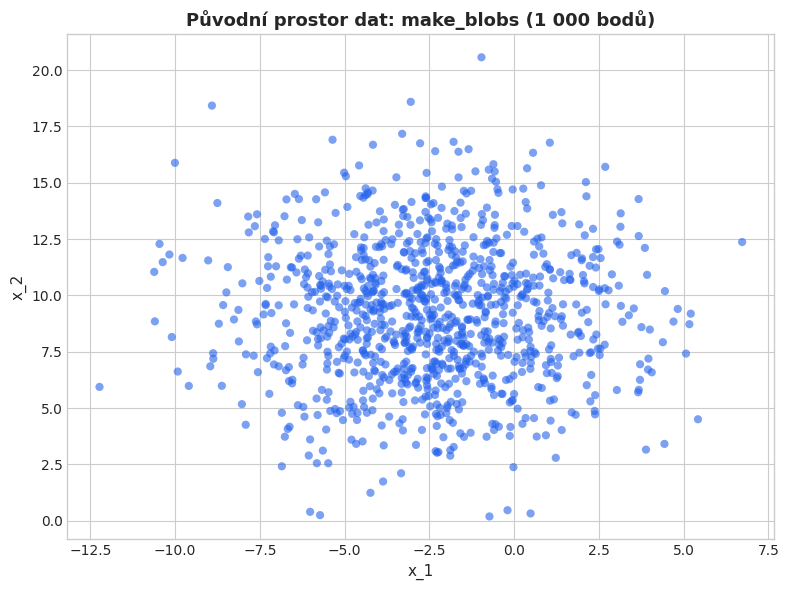

In [3]:
# Vykreslení původního bodového grafu
plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], c='#2563eb', alpha=0.6, s=35, edgecolors='none')
plt.title('Původní prostor dat: make_blobs (1 000 bodů)', fontsize=13, fontweight='bold')
plt.xlabel('x_1', fontsize=11)
plt.ylabel('x_2', fontsize=11)
plt.tight_layout()
plt.show()

## 3. Trénování modelu IsolationForest

Nastavíme 100 stromů (`n_estimators=100`), očekávaný podíl anomálií 5 % (`contamination=0.05`, tj. 50 bodů) a zafixujeme náhodný generátor `random_state=42`.

In [4]:
# Inicializace a trénování modelu Isolation Forest
isolation_forest = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

preds = isolation_forest.fit_predict(data)

# Vytvoření přehledného DataFrame (slajd 17)
blobs_df = pd.DataFrame(data, columns=['x_1', 'x_2'])
blobs_df['is_anomaly'] = preds

normal_points_df = blobs_df[blobs_df['is_anomaly'] == 1]
anomaly_points_df = blobs_df[blobs_df['is_anomaly'] == -1]

print(f'Počet běžných bodů (inliers): {len(normal_points_df)}')
print(f'Počet detekovaných anomálií (outliers): {len(anomaly_points_df)}')
print(f'Ověření podílu anomálií: {len(anomaly_points_df) / len(blobs_df) * 100:.1f} %')

Počet běžných bodů (inliers): 950
Počet detekovaných anomálií (outliers): 50
Ověření podílu anomálií: 5.0 %


## 4. Vizualizace detekovaných anomálií

Běžné body zobrazíme modře a detekované anomálie červeně, přesně podle slajdů 18–19.

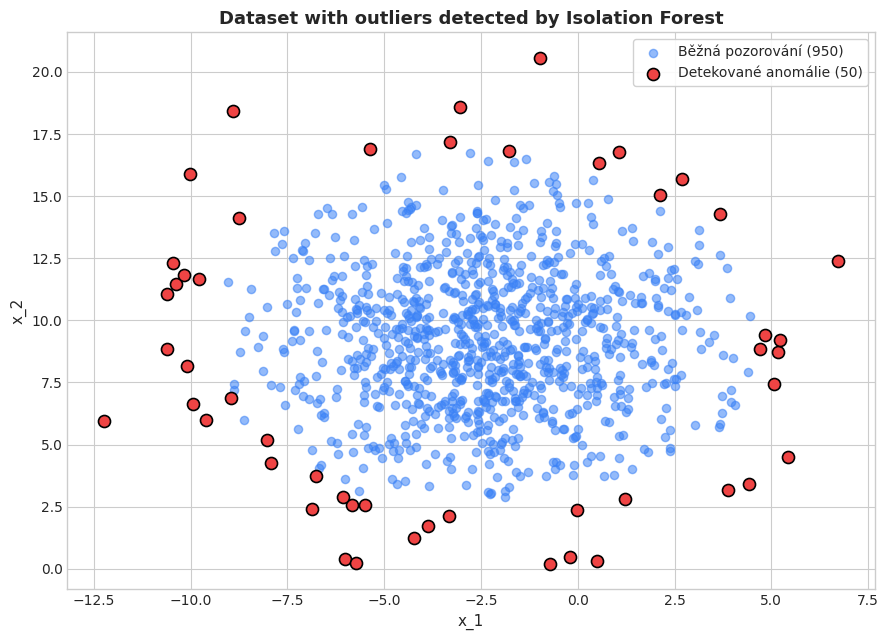

In [5]:
# Vykreslení výsledků (slajd 18)
plt.figure(figsize=(9, 6.5))
plt.scatter(normal_points_df['x_1'], normal_points_df['x_2'], color='#3b82f6', label='Běžná pozorování (950)', alpha=0.55, s=35)
plt.scatter(anomaly_points_df['x_1'], anomaly_points_df['x_2'], color='#ef4444', label='Detekované anomálie (50)', s=75, edgecolors='black', linewidth=1.2, zorder=5)
plt.title('Dataset with outliers detected by Isolation Forest', fontsize=13, fontweight='bold')
plt.xlabel('x_1', fontsize=11)
plt.ylabel('x_2', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

## 5. Spojité anomální skóre a rozhodovací funkce

Metoda `.decision_function()` vrací skóre, kde záporné hodnoty značí anomálii a kladné hodnoty běžný bod (slajd 20).

,x_1,x_2,is_anomaly,anomaly_score
0,0.5817,9.7307,1,0.1629
1,-2.4132,6.7540,1,0.1708
2,-2.2102,7.5039,1,0.1889
3,-5.0904,7.8606,1,0.1454
4,-1.5284,8.3570,1,0.1976
5,-1.0550,6.4752,1,0.1533
6,1.8146,4.7067,1,0.0539
7,-4.2962,13.1376,1,0.1334
8,-3.9223,9.7104,1,0.1783
9,-2.5719,9.3663,1,0.1972


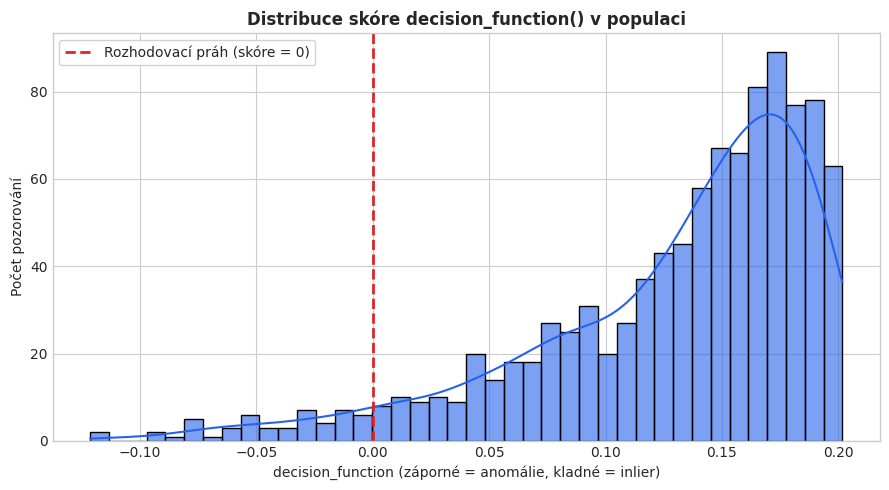

In [6]:
# Získání spojitého skóre rozhodovací funkce
blobs_df['anomaly_score'] = isolation_forest.decision_function(data)
display(blobs_df.head(10).round(4))

# Distribuce skóre rozhodovací funkce
plt.figure(figsize=(9, 5))
sns.histplot(blobs_df['anomaly_score'], bins=40, kde=True, color='#2563eb', alpha=0.6)
plt.axvline(0.0, color='#dc2626', linestyle='--', linewidth=2, label='Rozhodovací práh (skóre = 0)')
plt.title('Distribuce skóre decision_function() v populaci', fontsize=12, fontweight='bold')
plt.xlabel('decision_function (záporné = anomálie, kladné = inlier)')
plt.ylabel('Počet pozorování')
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

## 6. Rozhodovací plocha v 2D prostoru (Decision Boundary)

Vygenerujeme 2D mřížku a zobrazíme izočáry rozhodovací funkce. Všimněte si charakteristických pravoúhlých přechodů způsobených stromovým dělením podél souřadnicových os.

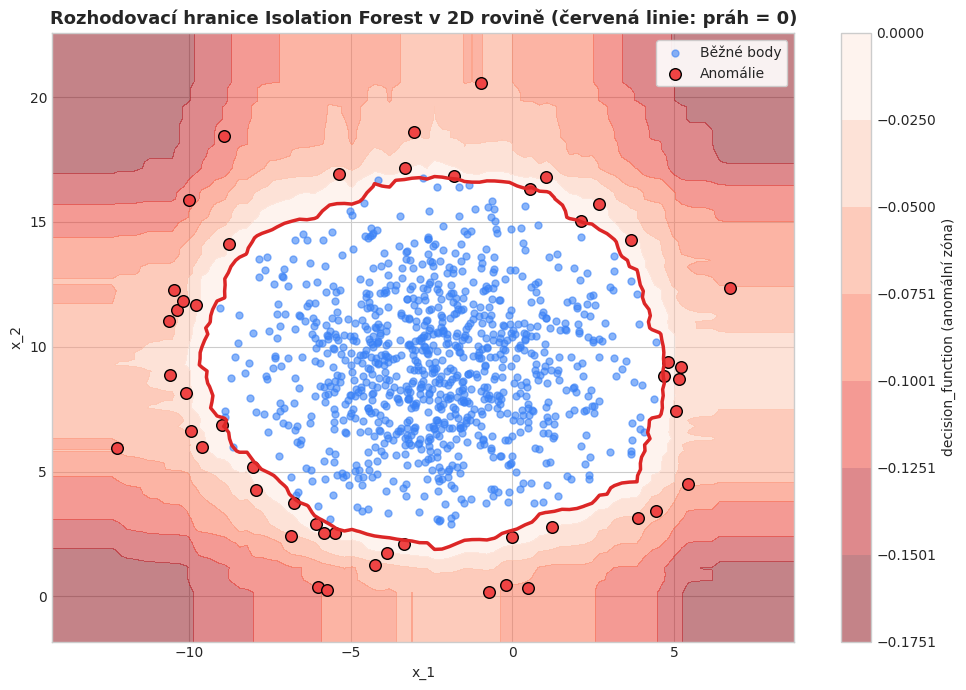

In [7]:
# Vytvoření 2D mřížky pro konturový graf
x_min, x_max = data[:, 0].min() - 2, data[:, 0].max() + 2
y_min, y_max = data[:, 1].min() - 2, data[:, 1].max() + 2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
Z = isolation_forest.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, Z, levels=np.linspace(Z.min(), 0, 8), cmap=plt.cm.Reds_r, alpha=0.5)
plt.colorbar(label='decision_function (anomální zóna)')
plt.contour(xx, yy, Z, levels=[0], linewidths=2.5, colors='#dc2626')
plt.scatter(normal_points_df['x_1'], normal_points_df['x_2'], c='#3b82f6', s=25, alpha=0.6, label='Běžné body')
plt.scatter(anomaly_points_df['x_1'], anomaly_points_df['x_2'], c='#ef4444', s=70, edgecolors='black', label='Anomálie')
plt.title('Rozhodovací hranice Isolation Forest v 2D rovině (červená linie: práh = 0)', fontsize=13, fontweight='bold')
plt.xlabel('x_1')
plt.ylabel('x_2')
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

## 7. Závěry a shrnutí

1. **Přímá izolace:** Isolation Forest cíleně izoluje vzácná a vzdálená pozorování v mělkých hloubkách náhodných stromů.
2. **Lineární škálovatelnost:** Na rozdíl od LOF ($O(N^2)$) má iForest složitost $O(t \cdot \psi \log \psi)$, díky čemuž bez problémů škáluje na miliony řádků.
3. **Invariance vůči škálování:** Nepotřebuje `StandardScaler`, protože stromové řezy závisí pouze na monotónním pořadí hodnot.
4. **Kontaminace a rozhodovací funkce:** Parametr `contamination=0.05` posouvá práh funkce `.decision_function()`, čímž přesně 5 % bodů s nejnižším skóre označí za anomálie (`-1`).